Linear Regression (No Reg) | MSE: 0.0126 | R2: 1.0000
Ridge (L2)                | MSE: 0.5244 | R2: 1.0000
Lasso (L1)                | MSE: 0.1390 | R2: 1.0000
Elastic Net (L1 + L2)     | MSE: 172.9885 | R2: 0.9969


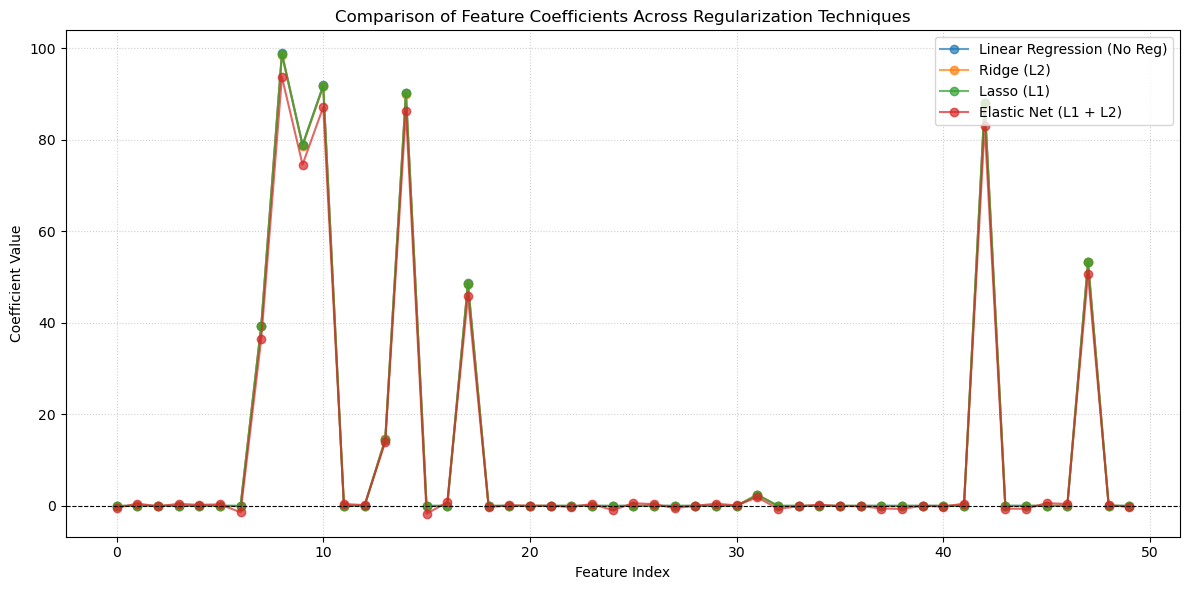

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

# Generate a regression dataset
X, y = make_regression(n_samples=500, n_features=50, n_informative=10, noise=0.1, random_state=42)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    "Linear Regression (No Reg)": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=0.1),
    "Elastic Net (L1 + L2)": ElasticNet(alpha=0.1, l1_ratio=0.5)
}

# Train and evaluate models
results = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results[name] = {
        "model": model,
        "mse": mse,
        "r2": r2,
        "coefficients": model.coef_
    }
    print(f"{name:25} | MSE: {mse:.4f} | R2: {r2:.4f}")

# Visualize coefficient shrinkage/sparsity
plt.figure(figsize=(12, 6))
for name, res in results.items():
    plt.plot(res["coefficients"], marker='o', linestyle='-', label=name, alpha=0.7)

plt.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlabel("Feature Index")
plt.ylabel("Coefficient Value")
plt.title("Comparison of Feature Coefficients Across Regularization Techniques")
plt.legend(loc="upper right")
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()